# PROJECT MD

Nama: Daniel Sebastian Winata  
NIM: 2802392652   
Dataset: C

# Library yang Digunakan

## Data Handling

pandas digunakan untuk membaca dan mengolah dataset dalam bentuk DataFrame.

numpy digunakan untuk operasi numerik dan penanganan nilai kosong.

## Visualisasi untuk EDA

matplotlib digunakan untuk membuat visualisasi dasar seperti grafik distribusi dan confusion matrix.

seaborn digunakan untuk membuat visualisasi EDA yang lebih informatif seperti boxplot dan heatmap.

## Utility Umum

os digunakan untuk membuat folder proyek dan mengecek keberadaan file dataset.

re digunakan untuk membersihkan string kotor dan mengubah data teks menjadi format numerik.

warnings digunakan untuk menyembunyikan peringatan yang tidak memengaruhi proses utama.

## Preprocessing dan Modeling dengan Scikit-learn

train_test_split digunakan untuk membagi data menjadi data training dan testing secara terstratifikasi.

ColumnTransformer digunakan untuk menggabungkan preprocessing fitur numerik dan kategorikal.

StandardScaler digunakan untuk menyamakan skala fitur numerik.

OneHotEncoder digunakan untuk mengubah kategori tanpa urutan menjadi fitur numerik.

LogisticRegression digunakan sebagai model baseline linear untuk klasifikasi.

DecisionTreeClassifier digunakan sebagai model klasifikasi berbasis aturan pohon keputusan.

KNeighborsClassifier digunakan untuk melakukan klasifikasi berdasarkan data terdekat.

RandomForestClassifier digunakan sebagai model ensemble dari banyak decision tree.

GradientBoostingClassifier digunakan sebagai model ensemble yang meningkatkan performa secara bertahap.

GridSearchCV digunakan untuk mencari kombinasi hyperparameter terbaik.

accuracy_score digunakan untuk mengukur persentase prediksi yang benar.

precision_score digunakan untuk mengukur ketepatan prediksi pada setiap kelas.

recall_score digunakan untuk mengukur kemampuan model menemukan data dari setiap kelas.

f1_score digunakan untuk menyeimbangkan nilai precision dan recall.

classification_report digunakan untuk menampilkan ringkasan metrik evaluasi setiap kelas.

confusion_matrix digunakan untuk melihat jumlah prediksi benar dan salah pada setiap kelas.

ConfusionMatrixDisplay digunakan untuk menampilkan confusion matrix dalam bentuk visual.

## Model Persistence

joblib digunakan untuk menyimpan model dan preprocessor dengan ukuran file yang lebih kecil.

pickle digunakan untuk menyimpan metadata ringan seperti nama kolom.

json digunakan untuk menyimpan hasil evaluasi model dalam format yang mudah dibaca.

## Experiment Tracking

mlflow digunakan untuk mencatat parameter, metrik, dan model dari setiap eksperimen.


In [38]:
import os
import re
import json
import pickle
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import mlflow
import mlflow.sklearn

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

sns.set(style='whitegrid')
pd.set_option('display.max_columns', None)

## OOP kelas kelasnya

dibuat per tahap (ingestion -> preprocessing -> training -> evaluation) dalam bentuk class biar:
1. setiap tahap independen dan gampang ditest satu-satu
2. gampang dipisah jadi file .py sendiri-sendiri kalau nanti project ini mau dirapihin jadi pipeline yang bisa di-run() ulang tanpa buka notebook lagi (gak harus klik run all manual tiap kali ada data baru)

In [20]:
class DataIngestion:
    # 
    #load dataset mentah + siapin struktur folder project
    #(data/, models/, metrics/, logs/) supaya tahap-tahap berikutnya
    #(preprocessing, training, evaluation) udah ada tempat nyimpen artefaknya.
    #

    def __init__(self, data_path: str):
        self.data_path = data_path
        self.df = None
        self._create_directories()


    def _create_directories(self):

        # buat 4 folder utama di direktori proyek jika belum ada
        directories = ['data', 'models', 'metrics', 'logs']
        for directory in directories:
            os.makedirs(directory, exist_ok=True)
            print(f"[INFO] Folder '{directory}' siap digunakan.")



    def load_data(self) -> pd.DataFrame:
        # BACA FILE
        if not os.path.exists(self.data_path):
            raise FileNotFoundError(f"[ERROR] File data tidak ditemukan di path: {self.data_path}")

        self.df = pd.read_csv(self.data_path)
        print(f"[INFO] Data berhasil dimuat. Ukuran dataset: {self.df.shape}")
        return self.df


    def inspect(self):
        
        # khusus EDA: liat info & describe dataset, gak dibawa ke versi produksi
        print('df.info()')
        self.df.info()
        print('\ndf.describe()')
        display(self.df.describe(include='all'))

    def check_missing(self) -> pd.DataFrame:
        # return df sum missing values
        if self.df is None:
            raise ValueError("Data belum di-load. Jalankan .load_data() terlebih dahulu.")

        missing = self.df.isnull().sum()
        missing = missing[missing > 0].sort_values(ascending=False)
        missing_pct = (missing / len(self.df) * 100).round(2)
        missing_df = pd.DataFrame({'missing count': missing, 'persentase missing (%)': missing_pct})

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.barh(missing_df.index, missing_df['persentase missing (%)'], color='#e67e22')
        ax.set_xlabel('missing values (%)')
        ax.set_title('missing values per kolom', fontsize=12, fontweight='bold')
        for i, (idx, row) in enumerate(missing_df.iterrows()):
            ax.text(row['persentase missing (%)'] + 0.1, i, f"{row['persentase missing (%)']:.1f}%", va='center')
        plt.tight_layout()
        plt.show()

        return missing_df

    def plot_target_distribution(self, target_col: str = 'Credit_Score'):
        # bar chart distribusi kelas target
        if self.df is None:
            raise ValueError("Data belum di-load. Jalankan .load_data() terlebih dahulu.")

        print(f'Distribusi {target_col}:')
        print(self.df[target_col].value_counts())
        print()
        print('Persentase:')
        print(self.df[target_col].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

        order = ['Poor', 'Standard', 'Good']
        colors = ["#ff1900", "#ff9d00", "#00ff6a"]

        counts = self.df[target_col].value_counts().reindex(order, fill_value=0)

        fig, ax = plt.subplots(figsize=(7, 4))
        bars = ax.bar(order, counts.values, color=colors, edgecolor='white', linewidth=0.8)

        for bar, val in zip(bars, counts.values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                    f'{val:,}\n({val/len(self.df) * 100:.1f}%)', ha='center', va='bottom', fontsize=10)

        ax.set_title(f'Distribusi {target_col} (Target Variable)', fontsize=13, fontweight='bold')
        ax.set_xlabel(target_col)
        ax.set_ylabel('Jumlah Nasabah')
        ax.set_ylim(0, counts.max() * 1.2)
        plt.tight_layout()
        plt.show()

In [ ]:
class DataPreprocessor:
    
    # Class untuk membersihkan data, memisahkan train/test, dan membangun pipeline transformasi.
    
    def __init__(self, target_column: str, test_size: float = 0.2, random_state: int = 42): # RATIO SPLIT 80:20
        self.target_column = target_column
        self.test_size = test_size
        self.random_state = random_state
        self.preprocessor = None
        self.num_cols = []
        self.cat_cols = []

    @staticmethod
    def _clean_numeric(series: pd.Series) -> pd.Series:
        cleaned = series.astype(str).str.replace(r'[^0-9.]', '', regex=True)
        return pd.to_numeric(cleaned, errors='coerce')

    @staticmethod
    def _parse_credit_age(s) -> float:
        if pd.isna(s):
            return np.nan
        years = re.search(r'(\d+)\s+Year', str(s))
        months = re.search(r'(\d+)\s+Month', str(s))
        y = int(years.group(1)) if years else 0
        m = int(months.group(1)) if months else 0
        return y * 12 + m

    def clean_data(self, df: pd.DataFrame) -> pd.DataFrame:
        
        # HANYA melakukan pembersihan struktural (drop kolom, fix tipe data, regex
        # TIDAK BOLEH ada imputasi missing values atau handling outlier berbasis statistik di sini
        
        df = df.copy()

        target_drops = [
            'unnamed: 0', 'id', 'customer_id', 'name',
            'ssn', 'month', 'type_of_loan', 'backlogs',
            'total_emi_per_month', 'monthly_inhand_salary',
            'credit_utilization_ratio', 'payment_of_min_amount',
            'num_credit_card', 'num_credit_inquiries',
            'delay_from_due_date', 'monthly_balance',
            'interest_rate', 'num_bank_accounts'
        ]

        df = df.drop(columns=[col for col in df.columns if col.lower() in target_drops])

        str_num_cols = [
            'Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment',
            'Changed_Credit_Limit', 'Outstanding_Debt', 'Amount_invested_monthly'
        ]
        for col in str_num_cols:
            if col in df.columns:
                df[col] = self._clean_numeric(df[col])

        if 'Credit_History_Age' in df.columns:
            df['Credit_History_Age'] = df['Credit_History_Age'].apply(self._parse_credit_age)

        # Outlier handling dengan batasan absolut (tidak apaapa dilakukan sebelum split)
        if 'Age' in df.columns:
            df.loc[(df['Age'] < 18) | (df['Age'] > 100), 'Age'] = np.nan
        if 'Num_of_Loan' in df.columns:
            df.loc[df['Num_of_Loan'] < 0, 'Num_of_Loan'] = np.nan

        if 'Occupation' in df.columns:
            df['Occupation'] = df['Occupation'].replace('_______', np.nan)
        if 'Credit_Mix' in df.columns:
            df['Credit_Mix'] = df['Credit_Mix'].replace('_', np.nan)
        if 'Payment_Behaviour' in df.columns:
            df['Payment_Behaviour'] = df['Payment_Behaviour'].replace('!@9#%8', np.nan)

        print("[CLEANING] Pembersihan kotor struktural berhasil.")
        return df

    def split_data(self, df: pd.DataFrame):
        
        # Membagi data SEBELUM imputasi statistik dilakukan.
        
        X = df.drop(columns=[self.target_column])
        y = df[self.target_column]

        # Ambil daftar kolom setelah data dibersihkan dan target dipisah
        self.num_cols = list(X.select_dtypes(include=['int64', 'float64']).columns)
        self.cat_cols = list(X.select_dtypes(include=['object', 'category']).columns)

        return train_test_split(
            X, y, test_size=self.test_size, random_state=self.random_state, stratify=y
        )

    def fit_transform(self, X_train: pd.DataFrame) -> pd.DataFrame:
        """
        Membangun dan melatih pipeline preprocessor menggunakan SimpleImputer.
        """
        # Pipeline Numerik: Imputasi Median -> Standardisasi
        numeric_transformer = Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ])

        # Pipeline Kategorikal: Imputasi Modus -> One Hot Encoding
        categorical_transformer = Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ])

        self.preprocessor = ColumnTransformer(
            transformers=[
                ('num', numeric_transformer, self.num_cols),
                ('cat', categorical_transformer, self.cat_cols)
            ]
        )

        # Proses transformasi
        X_train_trans = self.preprocessor.fit_transform(X_train)

        # Simpan objek preprocessor
        joblib.dump(self.preprocessor, 'models/preprocessor.pkl', compress=3)

        print(f"[INFO] Preprocessor siap. (Memproses {len(self.num_cols)} numerik & {len(self.cat_cols)} kategorikal)")
        return X_train_trans

    def transform(self, X_test: pd.DataFrame) -> pd.DataFrame:
        if self.preprocessor is None:
            raise ValueError("[ERROR] Preprocessor belum dilatih melalui fit_transform!")
        return self.preprocessor.transform(X_test)

In [ ]:
class ModelTrainer:
    """
    Class untuk melatih baseline model, melakukan tuning, 
    dan secara dinamis memilih serta menyimpan model dengan evaluasi terbaik.
    """

    BASELINE_MODELS = {
        'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
        'Decision Tree':       DecisionTreeClassifier(class_weight='balanced', random_state=42),
        'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=11),
        'Random Forest':       RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
        'Gradient Boosting':   GradientBoostingClassifier(n_estimators=100, random_state=42)
    }

    def __init__(self, X_train, y_train, X_test, y_test, random_state: int = 42):
        self.X_train = X_train
        self.y_train = y_train
        self.X_test  = X_test
        self.y_test  = y_test
        self.random_state = random_state
        
        self.baseline_results = []
        self.tuned_results    = []
        self.trained_models   = {} # [BARU] Tempat menyimpan semua objek model yang sudah di-fit
        
        self.best_model = None
        self.best_name  = None

    def _score(self, name: str, y_pred) -> dict:
        return {
            'Model':           name,
            'Accuracy':        accuracy_score(self.y_test, y_pred),
            'Macro Precision': precision_score(self.y_test, y_pred, average='macro', zero_division=0),
            'Macro Recall':    recall_score(self.y_test, y_pred, average='macro', zero_division=0),
            'Macro F1':        f1_score(self.y_test, y_pred, average='macro', zero_division=0),
        }

    def run_baseline(self) -> pd.DataFrame:
        print("[INFO] Memulai training model baseline...")
        self.baseline_results = []
        
        for name, model in self.BASELINE_MODELS.items():
            print(f'Training {name}...', end=' ')
            model.fit(self.X_train, self.y_train)
            
            # [BARU] Simpan model yang sudah dilatih ke dalam dictionary
            self.trained_models[name] = model 
            
            y_pred = model.predict(self.X_test)
            row = self._score(name, y_pred)
            self.baseline_results.append(row)
            print(f"Accuracy={row['Accuracy']:.4f}, Macro F1={row['Macro F1']:.4f}")

        return pd.DataFrame(self.baseline_results).sort_values('Macro F1', ascending=False).reset_index(drop=True)

    def train_and_tune(self) -> tuple:
        print('\n[INFO] Memulai Hyperparameter Tuning...')
        



        # Tuning Random Forest
        rf_param_grid = {
            'n_estimators':      [100, 200],
            'max_depth':         [10, 20, 30],
            'min_samples_split': [2, 5, 10]
        }
        rf_grid = GridSearchCV(
            RandomForestClassifier(class_weight='balanced', random_state=self.random_state, n_jobs=-1),
            rf_param_grid, cv=3, scoring='f1_macro', n_jobs=-1
        )

        with mlflow.start_run(run_name="Tuning_RandomForest", nested=True):
            rf_grid.fit(self.X_train, self.y_train)
            rf_pred = rf_grid.best_estimator_.predict(self.X_test)
            rf_f1 = f1_score(self.y_test, rf_pred, average='macro')
            mlflow.log_params(rf_grid.best_params_)
            mlflow.log_metric("val_macro_f1", rf_f1)
            mlflow.sklearn.log_model(rf_grid.best_estimator_, "model_RandomForest")

        print(f'Best RF params  : {rf_grid.best_params_}')
        



        # Tuning Gradient Boosting 
        gb_param_grid = {
            'n_estimators':  [100, 200],
            'max_depth':     [3, 5],
            'learning_rate': [0.05, 0.1, 0.2]
        }
        gb_grid = GridSearchCV(
            GradientBoostingClassifier(random_state=self.random_state),
            gb_param_grid, cv=3, scoring='f1_macro', n_jobs=-1
        )

        with mlflow.start_run(run_name="Tuning_GradientBoosting", nested=True):
            gb_grid.fit(self.X_train, self.y_train)
            gb_pred = gb_grid.best_estimator_.predict(self.X_test)
            gb_f1 = f1_score(self.y_test, gb_pred, average='macro')
            mlflow.log_params(gb_grid.best_params_)
            mlflow.log_metric("val_macro_f1", gb_f1)
            mlflow.sklearn.log_model(gb_grid.best_estimator_, "model_GradientBoosting")

        print(f'Best GB params  : {gb_grid.best_params_}')




        # Evaluasi Hasil Tuning
        tuned_models = {
            'Random Forest (Tuned)':     rf_grid.best_estimator_,
            'Gradient Boosting (Tuned)': gb_grid.best_estimator_
        }
        
        # [BARU] Gabungkan model hasil tuning ke dalam dictionary utama
        self.trained_models.update(tuned_models)
        
        self.tuned_results = []
        for name, model in tuned_models.items():
            y_pred = model.predict(self.X_test)
            self.tuned_results.append(self._score(name, y_pred))




        # seleksi Final Otomatis
        all_results = pd.DataFrame(self.baseline_results + self.tuned_results)\
                        .sort_values('Macro F1', ascending=False).reset_index(drop=True)
        
        # ambil nama model pemenang
        self.best_name = all_results.iloc[0]['Model']
        
        # [BARU] sarik objek model yang benar-benar menang secara dinamis, apapun algoritmanya
        self.best_model = self.trained_models[self.best_name]

        print(f'\n====================================')
        print(f' MODEL TERBAIK: {self.best_name}')
        print(f' MACRO F1     : {all_results.iloc[0]["Macro F1"]:.4f}')
        print(f'====================================')

        # [BARU] simpan model pemenang sebagai artefak untuk inferencing.py
        joblib.dump(self.best_model, 'models/best_model.pkl', compress=('lzma', 9))
        print(f"[INFO] Artefak '{self.best_name}' berhasil disimpan ke 'models/best_model.pkl'")

        return self.best_model, self.best_name, all_results

In [23]:
class ModelEvaluator:
    """
    Class untuk mengevaluasi model, menampilkan visualisasi di notebook, 
    dan mengekspor metrik serta metadata untuk kebutuhan produksi.
    """
    
    # Pastikan label ini sesuai dengan unik kategori di target_column kamu
    LABEL_ORDER = ['Poor', 'Standard', 'Good']

    def __init__(self, model, model_name: str, X_test, y_test, num_cols: list, cat_cols: list):
        self.model      = model
        self.model_name = model_name
        self.X_test     = X_test
        self.y_test     = y_test
        self.num_cols   = num_cols
        self.cat_cols   = cat_cols
        # Prediksi dilakukan sekali saat inisialisasi untuk menghemat komputasi
        self.y_pred     = self.model.predict(X_test)

 
    # FUNGSI VISUALISASI (HANYA UNTUK NOTEBOOK)
  

    def show_classification_report(self):
        print(f'Classification Report: {self.model_name}')
        print(classification_report(self.y_test, self.y_pred, labels=self.LABEL_ORDER))

    def plot_confusion_matrix(self):
        cm = confusion_matrix(self.y_test, self.y_pred, labels=self.LABEL_ORDER)
        fig, ax = plt.subplots(figsize=(7, 5))
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=self.LABEL_ORDER)
        disp.plot(ax=ax, colorbar=True, cmap='Blues')
        ax.set_title(f'Confusion Matrix - {self.model_name}', fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
        print('\nInterpretasi:')
        for i, lbl in enumerate(self.LABEL_ORDER):
            correct, total = cm[i, i], cm[i].sum()
            if total > 0:
                print(f'  {lbl}: {correct}/{total} benar ({correct/total*100:.1f}%)')
            else:
                print(f'  {lbl}: 0/0 benar (0.0%)')

    def plot_feature_importance(self, feature_names, top_n: int = 15):
        if not hasattr(self.model, 'feature_importances_'):
            print(f"[WARNING] Model {self.model_name} tidak memiliki atribut 'feature_importances_'.")
            return

        importances = self.model.feature_importances_
        n = min(len(feature_names), len(importances))
        fi_df = pd.DataFrame({'Feature': feature_names[:n], 'Importance': importances[:n]})\
                  .sort_values('Importance', ascending=False).head(top_n)

        fig, ax = plt.subplots(figsize=(9, 6))
        bars = ax.barh(fi_df['Feature'][::-1], fi_df['Importance'][::-1], color='#3498db')
        ax.set_title(f'Top {top_n} Feature Importance - {self.model_name}', fontsize=12, fontweight='bold')
        ax.set_xlabel('Importance Score')
        
        for bar in bars:
            ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
                    f'{bar.get_width():.4f}', va='center', fontsize=8)
        plt.tight_layout()
        plt.show()

    def summary(self):
        acc  = accuracy_score(self.y_test, self.y_pred)
        f1   = f1_score(self.y_test, self.y_pred, average='macro', zero_division=0)
        prec = precision_score(self.y_test, self.y_pred, average='macro', zero_division=0)
        rec  = recall_score(self.y_test, self.y_pred, average='macro', zero_division=0)

        print('        RINGKASAN MODEL TERBAIK')
        print(f'  Model              : {self.model_name}')
        print(f'  Accuracy           : {acc:.4f}  ({acc*100:.2f}%)')
        print(f'  Macro Precision    : {prec:.4f}')
        print(f'  Macro Recall       : {rec:.4f}')
        print(f'  Macro F1 Score     : {f1:.4f}')

   
    # FUNGSI PRODUKSI (UNTUK evaluation.py)


    def evaluate(self) -> dict:
        """
        Menghitung metrik utama, mengekspor ke JSON, dan log ke MLflow.
        """
        macro_f1 = f1_score(self.y_test, self.y_pred, average='macro', zero_division=0)
        accuracy = accuracy_score(self.y_test, self.y_pred)
        report = classification_report(self.y_test, self.y_pred, output_dict=True, zero_division=0)

        print("\n[EVALUASI FINAL]")
        print(f"Nama Model Terpilih : {self.model_name}")
        print(f"Akurasi             : {accuracy:.4f}")
        print(f"Macro F1-Score      : {macro_f1:.4f}")

        metrics_summary = {
            'model_name': self.model_name,
            'accuracy': accuracy,
            'macro_f1_score': macro_f1,
            'detailed_report': report
        }

        # Ekspor metrik ke JSON
        with open('metrics/evaluation_report.json', 'w') as f:
            json.dump(metrics_summary, f, indent=4)
        print("[INFO] Laporan performa diekspor ke 'metrics/evaluation_report.json'.")

        # Log ke MLflow
        with mlflow.start_run(run_name=f"Final_Evaluation_{self.model_name}", nested=True):
            mlflow.log_metric("test_accuracy", accuracy)
            mlflow.log_metric("test_macro_f1", macro_f1)
            # Model sudah di-log di tahap tuning, tapi jika ingin memastikan versi final tercatat:
            mlflow.sklearn.log_model(self.model, "best_model_deployment")

        return metrics_summary

    def save_artifacts(self):
        """
        Menyimpan metadata kolom. (Model utama sudah disimpan oleh ModelTrainer).
        """
        metadata = {
            'model_name': self.model_name,
            'numerical_columns': self.num_cols,
            'categorical_columns': self.cat_cols
        }
        
        with open('models/model_metadata.pkl', 'wb') as f:
            pickle.dump(metadata, f)

        print("[INFO] File 'model_metadata.pkl' berhasil diamankan di folder 'models/'.")


## Load Data


In [24]:
ingestion = DataIngestion('data_C.csv')
df = ingestion.load_data()
df.head()

[INFO] Folder 'data' siap digunakan.
[INFO] Folder 'models' siap digunakan.
[INFO] Folder 'metrics' siap digunakan.
[INFO] Folder 'logs' siap digunakan.
[INFO] Data berhasil dimuat. Ukuran dataset: (25000, 29)


,Unnamed: 0,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0,0x20419,CUS_0x36e1,August,Gellero,35,132-77-4921,Journalist,20364.57,1626.047500,6,8,32,3,"Personal Loan, Student Loan, and Mortgage Loan",23,9,10.3,11.0,Standard,2500.04,27.576478,9 Years and 8 Months,Yes,26.168109,92.51897591535379,High_spent_Small_value_payments,303.917665,Standard
1,1,0x4579,CUS_0x2a61,August,NaN,46,753-68-0048,Teacher,9786.86,951.571667,9,10,1663,2,"Personal Loan, and Student Loan",58,14,15.53,6.0,Standard,2149.9,23.451285,NaN,Yes,11.564437,54.46174813453877,Low_spent_Medium_value_payments,309.130981,Poor
2,2,0x1b923,CUS_0x788b,June,Ben Klaymane,19,276-42-6585,_______,146880.84,12372.070000,1,6,2,1,Auto Loan,25,4,5.04,1.0,Good,387.53,31.100297,24 Years and 3 Months,No,98.031931,478.3574716999517,High_spent_Small_value_payments,920.817597,Standard
3,3,0x8ac9,CUS_0x5534,April,Aubinr,39,246-34-3138,Developer,23200.82,NaN,3,7,5,0,NaN,30,15,24.73,6.0,Standard,987.07,26.786925,17 Years and 7 Months,Yes,0.000000,65.84983488267585,Low_spent_Large_value_payments,391.890332,Standard
4,4,0x24a41,CUS_0x104f,April,Markm,20,264-84-8069,Architect,11336.835,992.736250,4,1405,14,6,"Auto Loan, Payday Loan, Student Loan, Auto Loa...",30,19,16.44,7.0,Standard,177.98,24.001752,14 Years and 7 Months,Yes,35.562731,NaN,Low_spent_Small_value_payments,228.245999,Standard


dimensi dataset kita memiliki total 25000 baris pengamatan dengan 29 kolom

target prediksi kita kolom target kita adalah credit_score, yang berisi label klasifikasi (contoh: poor, standard, good)

kolom identifier (noise): ada beberapa kolom yang cuma berfungsi sebagai pengenal unik nasabah, seperti unnamed: 0, ID, customer_ID, name, dan SSN, ini gak punya nilai pola untuk model ML dan wajib banget di drop

missing value dan data kotor: nilai NaN langsung kelihatan secara kasat mata di kolom umur, gaji, dan bunga, serta ada data kosong yang nyamar pakai placeholder aneh, contohnya di baris kedua kolom occupation isinya cuma garis bawah _______

format fitur tidak ramah ML: tipe data di kolom credit_history_age itu teks panjang (misal: 9 years and 8 months), karena model ML cuma bisa ngunyah angka, ini harus banget kita konversi jadi angka total bulan

In [25]:
ingestion.inspect()

df.info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                25000 non-null  int64  
 1   ID                        25000 non-null  object 
 2   Customer_ID               25000 non-null  object 
 3   Month                     25000 non-null  object 
 4   Name                      22570 non-null  object 
 5   Age                       25000 non-null  object 
 6   SSN                       25000 non-null  object 
 7   Occupation                25000 non-null  object 
 8   Annual_Income             25000 non-null  object 
 9   Monthly_Inhand_Salary     21164 non-null  float64
 10  Num_Bank_Accounts         25000 non-null  int64  
 11  Num_Credit_Card           25000 non-null  int64  
 12  Interest_Rate             25000 non-null  int64  
 13  Num_of_Loan               25000 non-null  object 
 

,Unnamed: 0,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
count,25000.000000,25000,25000,25000,22570,25000,25000,25000,25000,21164.000000,25000.000000,25000.000000,25000.000000,25000,22148,25000.000000,23208,25000,24528.000000,25000,25000,25000.000000,22760,25000,25000.000000,23866,25000,24699.000000,25000
unique,NaN,25000,11254,8,8995,551,11061,16,12845,NaN,NaN,NaN,NaN,150,5731,NaN,235,3428,NaN,4,11257,NaN,403,3,NaN,22773,7,NaN,3
top,NaN,0x1fc32,CUS_0xb861,February,Langep,35,#F%$D@*&8,_______,35104.32,NaN,NaN,NaN,NaN,3,Not Specified,NaN,19,_,NaN,Standard,1298.38,NaN,17 Years and 11 Months,Yes,NaN,__10000__,Low_spent_Small_value_payments,NaN,Standard
freq,NaN,1,7,3203,14,743,1385,1765,7,NaN,NaN,NaN,NaN,3609,345,NaN,1370,518,NaN,9170,8,NaN,129,13082,NaN,1049,6377,NaN,13282
mean,12499.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4189.505970,18.075360,22.238000,75.407480,NaN,NaN,20.988400,NaN,NaN,28.449976,NaN,NaN,32.277257,NaN,NaN,1465.714590,NaN,NaN,403.454486,NaN
std,7217.022701,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3208.575501,122.375374,126.156225,478.786499,NaN,NaN,14.851345,NaN,NaN,197.078633,NaN,NaN,5.126823,NaN,NaN,8514.582351,NaN,NaN,215.613056,NaN
min,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,303.645417,-1.000000,0.000000,1.000000,NaN,NaN,-5.000000,NaN,NaN,0.000000,NaN,NaN,20.100770,NaN,NaN,0.000000,NaN,NaN,0.088628,NaN
25%,6249.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1611.188333,3.000000,4.000000,8.000000,NaN,NaN,10.000000,NaN,NaN,3.000000,NaN,NaN,28.043382,NaN,NaN,30.181528,NaN,NaN,269.935928,NaN
50%,12499.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3071.424583,6.000000,5.000000,14.000000,NaN,NaN,18.000000,NaN,NaN,6.000000,NaN,NaN,32.309314,NaN,NaN,68.248891,NaN,NaN,335.519841,NaN
75%,18749.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5941.093333,7.000000,7.000000,20.000000,NaN,NaN,28.000000,NaN,NaN,9.000000,NaN,NaN,36.488060,NaN,NaN,159.990097,NaN,NaN,472.202042,NaN


In [26]:
df['Type_of_Loan'].unique()

array(['Personal Loan, Student Loan, and Mortgage Loan',
       'Personal Loan, and Student Loan', 'Auto Loan', ...,
       'Student Loan, Debt Consolidation Loan, Home Equity Loan, Home Equity Loan, Not Specified, Mortgage Loan, and Student Loan',
       'Auto Loan, Not Specified, Auto Loan, Not Specified, Payday Loan, and Student Loan',
       'Home Equity Loan, Not Specified, Home Equity Loan, Debt Consolidation Loan, Mortgage Loan, and Debt Consolidation Loan'],
      dtype=object)

## Eksplorasi Data (EDA)

### mari kita lihat distribusi target kita (credit_score)

Distribusi Credit_Score:
Credit_Score
Standard    13282
Poor         7268
Good         4450
Name: count, dtype: int64

Persentase:
Credit_Score
Standard    53.13%
Poor        29.07%
Good         17.8%
Name: proportion, dtype: object


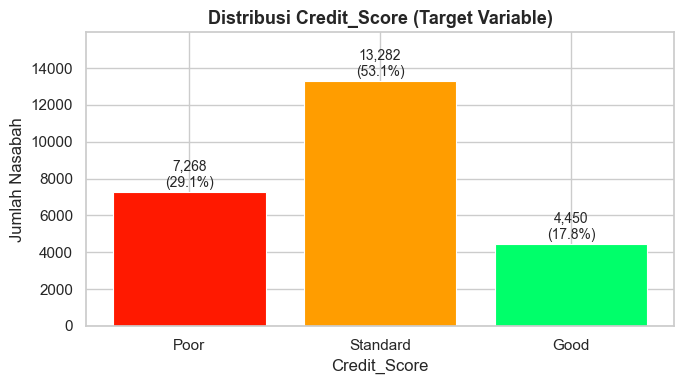

In [27]:
ingestion.plot_target_distribution('Credit_Score')

Distribusi target SANGAT tidak seimbang. Kelas Standard mendominasi (53%), diikuti Poor (29%) dan Good (18%).     
Kelas minority (Good) perlu diperhatikan saat evaluasi model  metric seperti macro-F1 akan lebih relevan daripada accuracy saja

### check missing values

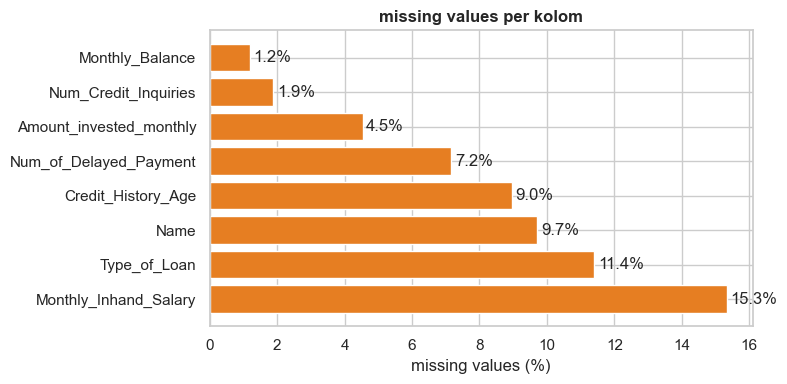

,missing count,persentase missing (%)
Monthly_Inhand_Salary,3836,15.34
Type_of_Loan,2852,11.41
Name,2430,9.72
Credit_History_Age,2240,8.96
Num_of_Delayed_Payment,1792,7.17
Amount_invested_monthly,1134,4.54
Num_Credit_Inquiries,472,1.89
Monthly_Balance,301,1.20


In [28]:
missing_df = ingestion.check_missing()
missing_df

kolom monthly_inhand_salary ada di peringkat pertama dengan persentase missing value tertinggi yaitu sekitar 15,34 persen atau sebanyak 3836 baris kosong kemudian disusul oleh type_of_loan dgn 11,41 persen dan name dengan 9,72 persen sementara itu kolom lainnya seperti credit_history_age hingga monthly_balance memiliki persentase data kosong yang tergolong aman yaitu di bawah 10 persen insight utama yang bisa kita ambil dr temuan ini adalah karena persentase kerusakan data tertinggi masih berada di kisaran 15 persen dan tidak ada yang menyentuh angka ekstrem kita sama sekali tidak perlu membuang keseluruhan kolom numerik tsb melainkan cukup menanganinya menggunakan teknik imputasi pengisian nilai seperti median yang mana ini sgtt membuktikan bahwa langkah kita menggunakan simpleimputer pada pipeline ML di tahap preprocessing tadi adalah keputusan yang paling tepat

### data kotor
Beberapa kolom numeric tersimpan sebagai string dan mengandung nilai tidak valid

In [29]:
# Contoh nilai tidak valid pada kolomkolom string

print('Age (sampel unik tidak valid):')

print([x for x in df['Age'].unique() if not str(x).lstrip('-').replace('.','',1).isdigit()][:10])



print('\nOccupation (unik):')

print(df['Occupation'].unique())



print('\nCredit_Mix (unik):')

print(df['Credit_Mix'].unique())



print('\nPayment_Behaviour (unik):')

print(df['Payment_Behaviour'].unique())



print('\nCredit_History_Age (unik):')

print(df['Credit_History_Age'].unique())

Age (sampel unik tidak valid):
['28_', '53_', '26_', '43_', '15_', '2756_', '19_', '29_', '32_', '18_']

Occupation (unik):
['Journalist' 'Teacher' '_______' 'Developer' 'Architect' 'Doctor'
 'Media_Manager' 'Accountant' 'Entrepreneur' 'Lawyer' 'Writer' 'Engineer'
 'Manager' 'Musician' 'Scientist' 'Mechanic']

Credit_Mix (unik):
['Standard' 'Good' 'Bad' '_']

Payment_Behaviour (unik):
['High_spent_Small_value_payments' 'Low_spent_Medium_value_payments'
 'Low_spent_Large_value_payments' 'Low_spent_Small_value_payments'
 '!@9#%8' 'High_spent_Medium_value_payments'
 'High_spent_Large_value_payments']

Credit_History_Age (unik):
['9 Years and 8 Months' nan '24 Years and 3 Months'
 '17 Years and 7 Months' '14 Years and 7 Months' '2 Years and 4 Months'
 '20 Years and 11 Months' '23 Years and 5 Months' '28 Years and 2 Months'
 '22 Years and 4 Months' '15 Years and 10 Months' '18 Years and 9 Months'
 '26 Years and 6 Months' '30 Years and 0 Months' '16 Years and 9 Months'
 '6 Years and 4 Months

insight:  
Age, Annual_Income, Num_of_Loan, Outstanding_Debt, dll. mengandung nilai dengan karakter tambahan (_, -) dan nilai negatif tidak valid    
Occupation memiliki nilai placeholder _______    
Credit_Mix memiliki nilai placeholder _     
Payment_Behaviour memiliki nilai noise !@9#%8     
dan Credit_History_Age berformat teks ('9 Years and 8 Months')  perlu dikonversi ke angka bulan.    

JUSTIFIKASI FITUR YANG DIBUANG

unnamed: 0 = hanya merupakan indeks tambahan dari file CSV
id = hanya menjadi identitas unik setiap baris   
customer_id = hanya menjadi identitas pelanggan dan dapat membuat model menghafal data.   
name = merupakan identitas pribadi yang tidak relevan untuk prediksi.   
ssn = merupakan nomor identitas pribadi dan tidak relevan sebagai fitur   
month = dapat membuat model terlalu bergantung pada pola waktu dalam dataset  
type_of_loan = memiliki terlalu banyak kombinasi kategori yang kompleks  
total_emi_per_month = informasinya sudah diwakili oleh fitur keuangan lain.  
monthly_inhand_salary = informasinya tumpang tindih dengan pendapatan bulanan.  
credit_utilization_ratio = nilainya terlalu bervariasi dan dapat menambah noise.   
payment_of_min_amount = format datanya tdk konsisten.  
num_credit_card = informasinya tumpang tindih dengan jumlah akun kredit.   
num_credit_inquiries = nilainya mudah berubah dan krg stabil
delay_from_due_date = informasinya sudah diwakili oleh fitur riwayat pembayaran lain.   
monthly_balance = merupakan hasil perhitungan dari fitur keuangan lain 
interest_rate = berpotensi jadi data leakage terhadap target  
num_bank_accounts = jumlah akun bank tdk langsung menunjukkan kualitas kredit pelanggan.   


### distribusi fitur2 Numerik

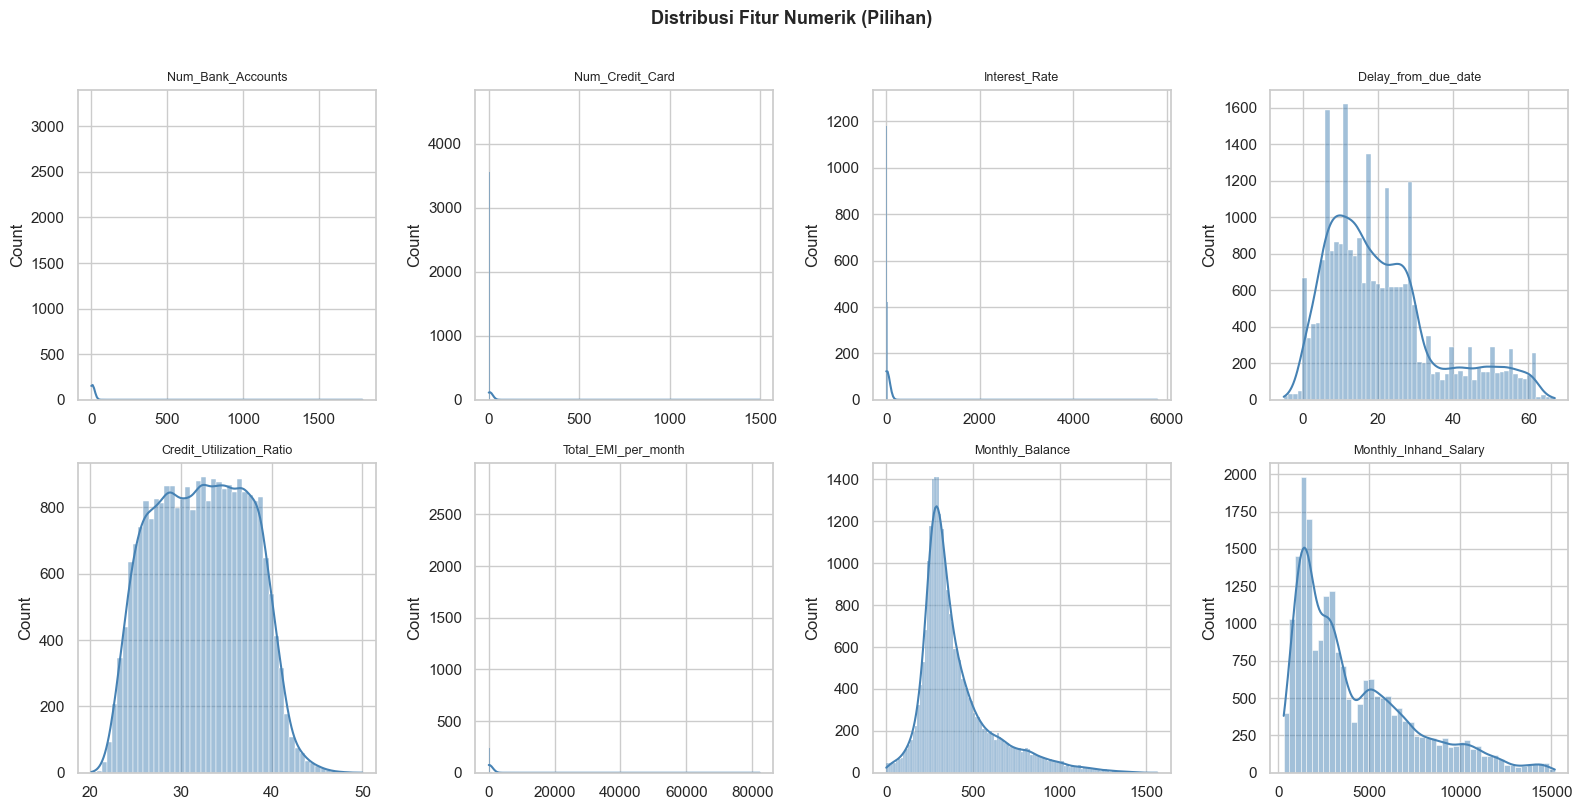

In [30]:
num_preview = ['Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate',
               'Delay_from_due_date', 'Credit_Utilization_Ratio',
               'Total_EMI_per_month', 'Monthly_Balance', 'Monthly_Inhand_Salary']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(num_preview):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('')

plt.suptitle('Distribusi Fitur Numerik (Pilihan)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

mayoritas fitur numerik menunjukkan distribusi right-skewed yang sangat ekstrem akibat kehadiran outlier kecuali rasio utilitas kredit yang terdistribusi secara normal, hal ini membuktikan bahwa langkah standardisasi menggunakan scaler yang sudah kita buat di dalam pipeline ML sangat krusial untuk dilakukan guna menstabilkan model

### fitur Numerik vs credit score (target) pakai boxplot

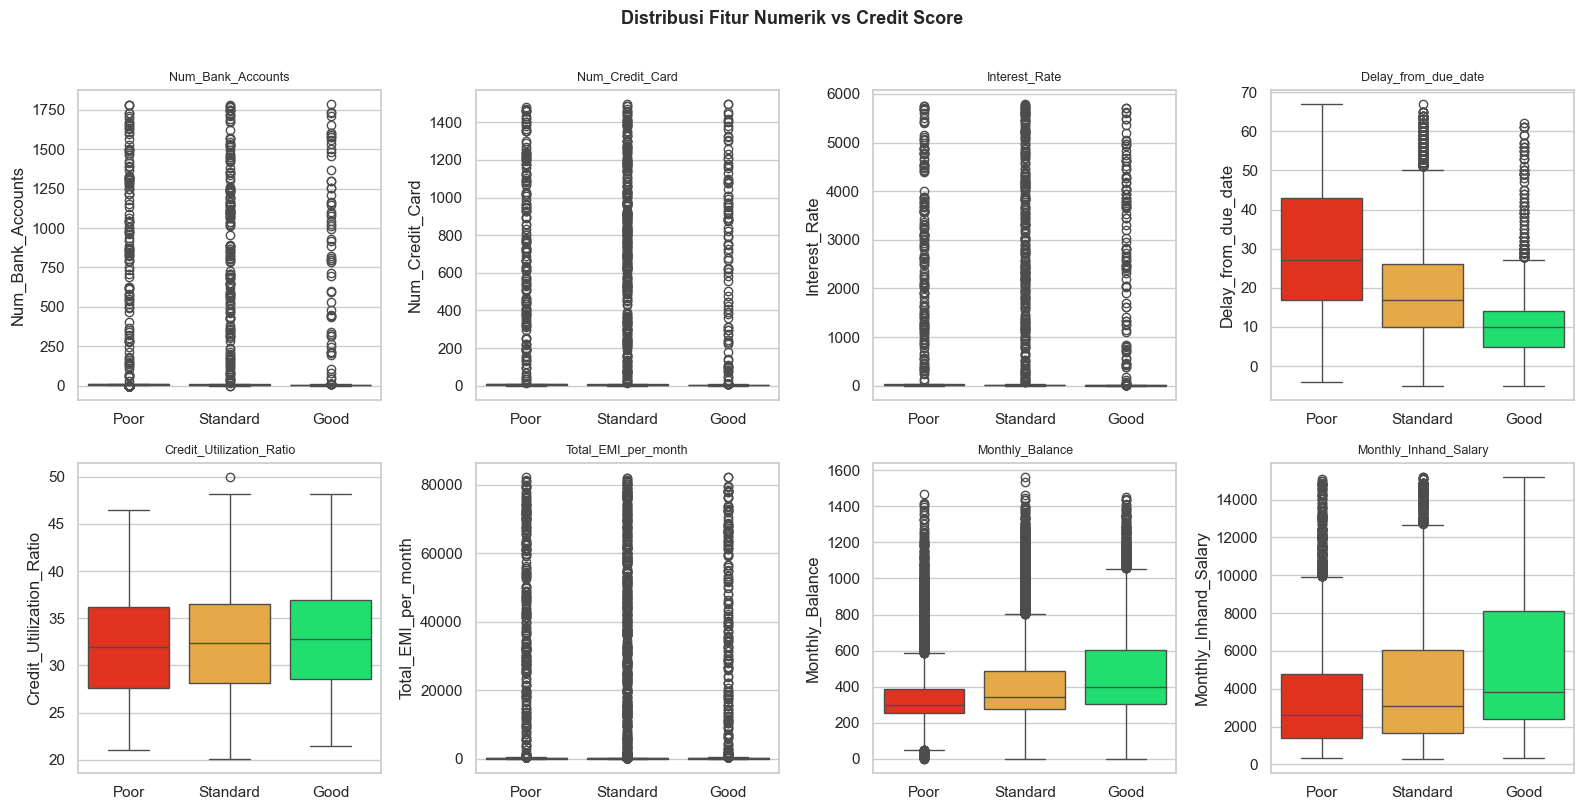

In [31]:
order = ['Poor', 'Standard', 'Good']
palette = {'Poor': "#ff1900", 'Standard': "#ffae2c", 'Good': "#00ff6a"}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(num_preview):
    sns.boxplot(x='Credit_Score', y=col, data=df, order=order,
                palette=palette, ax=axes[i])
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('')

plt.suptitle('Distribusi Fitur Numerik vs Credit Score', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

fitur yang paling kelihatan membedakan Credit Score adalah Delay_from_due_date dan Monthly_Inhand_Salary. Semakin baik credit score, keterlambatan pembayaran cenderung makin rendah, sementara pendapatan bulanan cenderung lebih tinggi.

monthly_Balance juga terlihat meningkat dari Poor ke Good, walaupun masih ada cukup banyak outlier. Sementara itu, fitur seperti Num_Bank_Accounts, Num_Credit_Card, Interest_Rate, dan Total_EMI_per_month punya outlier yang sangat banyak, jadi distribusinya kurang jelas dan kemungkinan perlu dicek lagi saat preprocessing. Credit_Utilization_Ratio sendiri terlihat relatif mirip di semua kategori, jadi pengaruhnya mungkin tidak terlalu kuat dibanding fitur lain.

### fitur Kategorikal vs Credit Score (target)

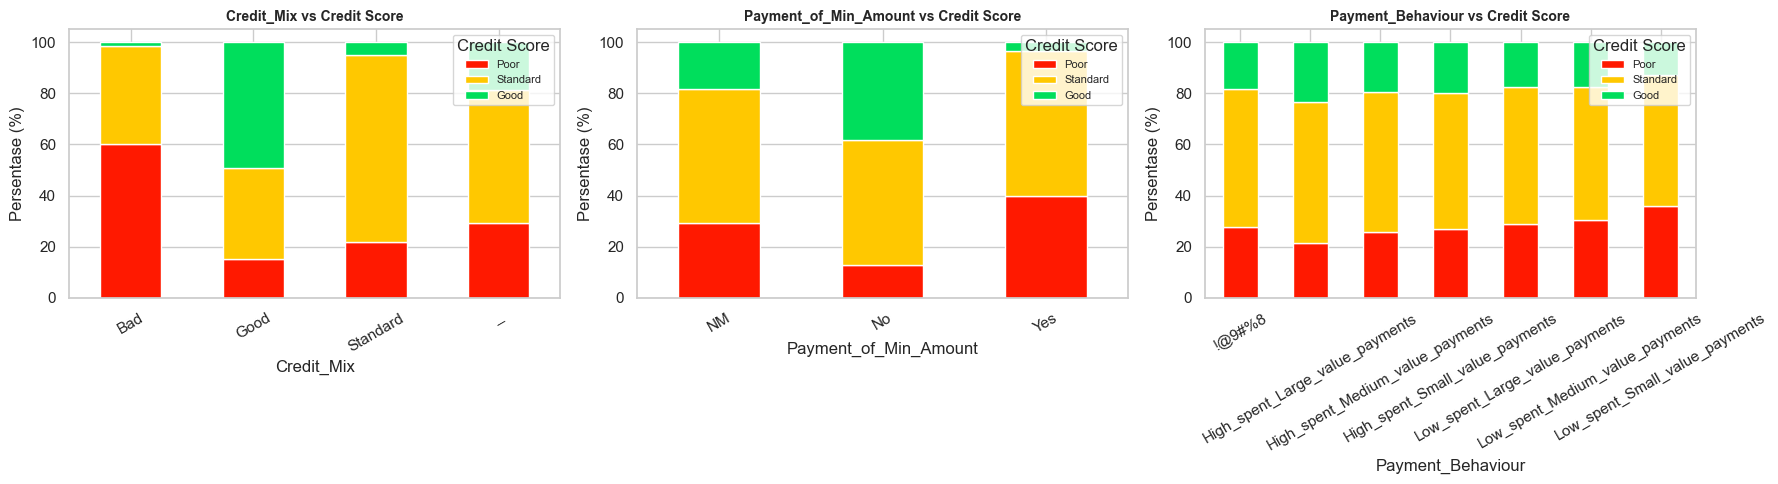

In [32]:
cat_cols_plot = ['Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']
order_cs = ['Poor', 'Standard', 'Good']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cat_cols_plot):
    ct = pd.crosstab(df[col], df['Credit_Score'], normalize='index') * 100
    ct = ct[order_cs]
    ct.plot(kind='bar', stacked=True, ax=axes[i],
            color=["#ff1900", "#ffc800", "#00de5c"],
            edgecolor='white')
    axes[i].set_title(f'{col} vs Credit Score', fontsize=10, fontweight='bold')
    axes[i].set_ylabel('Persentase (%)')
    axes[i].set_xlabel(col)
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].legend(title='Credit Score', loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

Credit_Mix terlihat punya hubungan yang cukup jelas dengan Credit Score. Kategori Good didominasi oleh credit score Good dan Standard, sedangkan kategori Bad punya proporsi credit score Poor paling tinggi. Jadi, kualitas campuran kredit kayak jenis dan kondisi kredit yang dimiliki nasabah cukup berpengaruh terhadap hasil credit score.

Pada Payment_of_Min_Amount, kategori No memiliki proporsi credit score Good paling besar. Artinya, nasabah yang tidak hanya membayar minimum cenderung punya kondisi kredit yang lebih baik. Sebaliknya, kategori Yes punya proporsi Poor yang lebih tinggi.

Untuk Payment_Behaviour, sebagian besar kategori masih didominasi oleh credit score Standard. Namun, kategori dengan pola pembayaran kecil terlihat punya proporsi Poor yang sedikit lebih tinggi, jadi perilaku pembayaran tetap bisa menjadi fitur pendukung untuk membedakan credit score.

### Correlation Heatmap

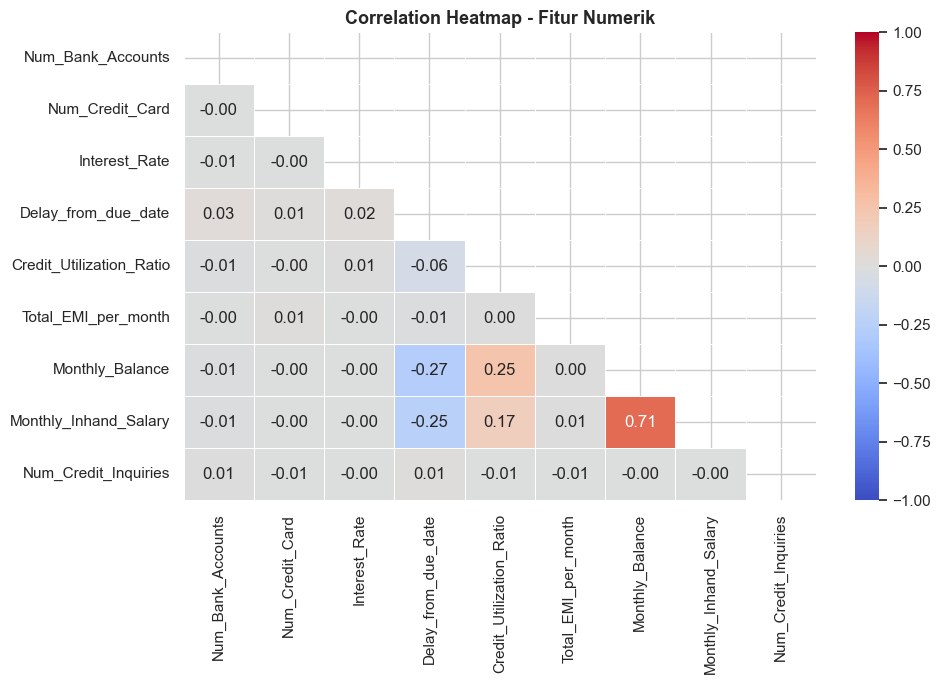

In [33]:
corr_cols = ['Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate',
             'Delay_from_due_date', 'Credit_Utilization_Ratio',
             'Total_EMI_per_month', 'Monthly_Balance',
             'Monthly_Inhand_Salary', 'Num_Credit_Inquiries']

corr_df = df[corr_cols].corr()

plt.figure(figsize=(10, 7))
mask = np.triu(np.ones_like(corr_df, dtype=bool))
sns.heatmap(corr_df, annot=True, cmap='coolwarm', fmt='.2f',
            mask=mask, linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap - Fitur Numerik', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

sebagian besar fitur finansial di sini sebenarnya tidak saling memengaruhi, kayak jumlah kartu kredit atau suku bunga yang angkanya hampir nol alias tidak ada hubungannya sama sekali. Hubungan yang paling berasa cuma ada di lingkaran gaji bersih bulanan, sisa saldo, dan keterlambatan bayar tagihan. Logikanya dapet banget: makin gede gaji bulanan seseorang, otomatis sisa saldo mereka di akhir bulan juga bakal makin tebal, kayak yang ditunjukkin sama korelasi kuat 0.71 di grafik. Sebaliknya, orang yang sering telat bayar tagihan cenderung punya pendapatan dan sisa saldo yang lebih mepet.

## Preprocessing & Feature Engineering

mau memakai DataPreprocessor untuk seluruh tahap cleaning, split, dan transformasi.    
bedanya sama versi awal: target_column sekarang di-pass pas inisialisasi class (bukan dataframe), karena dataframe-nya baru masuk pas method .clean_data(df) dipanggil  pola ini yang nantinya dipertahankan persis di preprocessing.py

### Pembersihan Data

In [34]:
preprocessor_obj = DataPreprocessor(target_column='Credit_Score')
df_clean = preprocessor_obj.clean_data(df)

[CLEANING] Pembersihan kotor struktural berhasil.


### Split Data & Definisikan Fitur

In [35]:
X_train, X_test, y_train, y_test = preprocessor_obj.split_data(df_clean)

num_cols = preprocessor_obj.num_cols
cat_cols = preprocessor_obj.cat_cols

print('Fitur Numerik    :', num_cols)
print('Fitur Kategorikal:', cat_cols)
print(f'Total fitur      : {len(num_cols) + len(cat_cols)}')

Fitur Numerik    : ['Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Outstanding_Debt', 'Credit_History_Age', 'Amount_invested_monthly']
Fitur Kategorikal: ['Occupation', 'Credit_Mix', 'Payment_Behaviour']
Total fitur      : 11


Digunakan stratify=y agar distribusi kelas tetap proporsional di kedua set. (JUGA BEST PRACTICE)

### Preprocessing PIPELINE

Pakai StandardScale buat numerik dan OneHotEncoder buat kategorikal (bukan OrdinalEncoder seperti percobaan sebelumnya), karena Occupation, Credit_Mix, dan Payment_Behaviour gak punya urutan natural. Hasil ColumnTransformer-nya langsung disimpan ke models/preprocessor.pkl lewat joblib (dengan compress) supaya pas inference nanti gak perlu fit ulang  cukup load file ini.

In [39]:
X_train_trans = preprocessor_obj.fit_transform(X_train)
X_test_trans  = preprocessor_obj.transform(X_test)

[INFO] Preprocessor siap. (Memproses 8 numerik & 3 kategorikal)


## Model
dicoba 5 model utk menemukan model terbaik:      

Logistic Regression = Baseline linear; cepat dan interpretatif     
Decision Tree = Non-linear, mudah diinterpretasi, tanpa scaling   
K-Nearest Neighbors = Instance-based, non-parametric   
Random Forest = Ensemble berbasis bagging; robust & powerful   
Gradient Boosting = Ensemble berbasis boosting; state-of-the-art untuk tabular   

### Setup Experiment Tracking (MLflow)

Sebelum mulai training, kita siapin dulu MLflow buat nge-log semua eksperimen (parameter, metric, model artifact) biar gak perlu nyatet manual. Semua run akan tersimpan di bawah satu experiment yang sama, jadi gampang dibandingin lewat MLflow UI nanti.

In [40]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("2802392652_DanielSebastianWinata_MDPROJECT_UAS")

# parent run buat nampung semua nested run training & evaluasi di notebook ini
mlflow.start_run(run_name="EDA_Notebook_Run")

2026/06/26 22:38:17 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/06/26 22:38:20 INFO mlflow.store.db.utils: Updating database tables
2026/06/26 22:40:13 INFO mlflow.tracking.fluent: Experiment with name '2802392652_DanielSebastianWinata_MDPROJECT_UAS' does not exist. Creating a new experiment.


<ActiveRun: >

### Eksperimen Awal (Baseline Tanpa Tuning)

In [41]:
trainer = ModelTrainer(X_train_trans, y_train, X_test_trans, y_test)
baseline_df = trainer.run_baseline()
baseline_df

[INFO] Memulai training model baseline...
Training Logistic Regression... Accuracy=0.6236, Macro F1=0.6110
Training Decision Tree... Accuracy=0.6032, Macro F1=0.5638
Training K-Nearest Neighbors... Accuracy=0.6392, Macro F1=0.6030
Training Random Forest... Accuracy=0.7002, Macro F1=0.6716
Training Gradient Boosting... Accuracy=0.6712, Macro F1=0.6457


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Random Forest,0.7002,0.678219,0.666570,0.671598
1,Gradient Boosting,0.6712,0.645906,0.653519,0.645682
2,Logistic Regression,0.6236,0.600076,0.635914,0.610967
3,K-Nearest Neighbors,0.6392,0.613977,0.596459,0.602957
4,Decision Tree,0.6032,0.565150,0.562579,0.563785


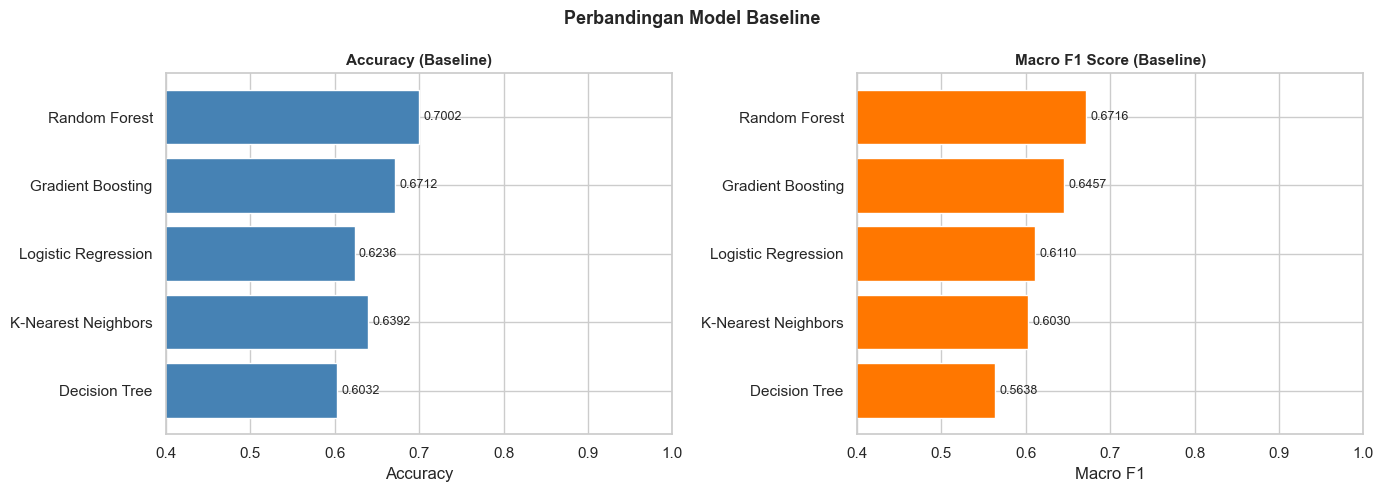

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, color, title in [
    (axes[0], 'Accuracy',  'steelblue',  'Accuracy (Baseline)'),
    (axes[1], 'Macro F1',  "#ff7700",    'Macro F1 Score (Baseline)'),
]:
    bars = ax.barh(baseline_df['Model'][::-1], baseline_df[metric][::-1], color=color)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlim(0.4, 1.0) # sesuaikan limit jika skor saya ternyata di bawah 0.4
    ax.set_xlabel(metric)
    
    for bar in bars:
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
                f'{bar.get_width():.4f}', va='center', fontsize=9)

plt.suptitle('Perbandingan Model Baseline', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Dua model terbaik dilakukan tuning untuk mengoptimalkan Macro F1. Method tune() dan select_best() yang dulu dipisah sekarang digabung jadi satu method train_and_tune(), biar konsisten sama implementasi final di train.py.

### Hyperparameter Tuning

In [43]:
best_model, best_name, all_results = trainer.train_and_tune()
display(all_results)


[INFO] Memulai Hyperparameter Tuning...


2026/06/26 22:42:13 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/06/26 22:42:15 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Best RF params  : {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}


2026/06/26 22:44:54 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/06/26 22:44:55 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Best GB params  : {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}

 MODEL TERBAIK: Random Forest (Tuned)
 MACRO F1     : 0.6762
[INFO] Artefak 'Random Forest (Tuned)' berhasil disimpan ke 'models/best_model.pkl'


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Random Forest (Tuned),0.6970,0.669756,0.688302,0.676219
1,Random Forest,0.7002,0.678219,0.666570,0.671598
2,Gradient Boosting (Tuned),0.6852,0.659351,0.660063,0.658908
3,Gradient Boosting,0.6712,0.645906,0.653519,0.645682
4,Logistic Regression,0.6236,0.600076,0.635914,0.610967
5,K-Nearest Neighbors,0.6392,0.613977,0.596459,0.602957
6,Decision Tree,0.6032,0.565150,0.562579,0.563785


WALAU AKURASI RANDOM FOREST TUNED LEBIH KECIL DARI RANDOM FOREST, MACRO F1nya lebih tinggi yang berarti model hasil tuning kita jauh lebih adil dan seimbang dalam memprediksi seluruh kategori pada kolom target credit_score terutama pada kelas minoritas seperti poor dan good

angka akurasi yang sedikit turun itu sangat wajar dan justru bagus karena itu menandakan model tidak lagi menebak kelas mayoritas atau kelas standard secara membabi buta hanya demi terlihat akurat di atas kertas

karena macro F1 menghitung rata-rata performa dari setiap kelas secara independen kenaikan metrik ini adalah bukti nyata bahwa parameter model kita sudah lebih optimal dan tidak terjebak pada bias data dominan sehingga sangat siap untuk dibawa ke tahap deployment di streamlit nanti

## Evaluasi Model Terbaik

Menggunakan ModelEvaluator untuk laporan lengkap. Perhatikan target (y_test) di sini masih berupa label string asli ('Poor'/'Standard'/'Good'), TIDAK di-encode jadi angka seperti percobaan sebelumnya  ini sengaja biar hasil prediksi model nanti pas inference langsung berupa label yang manusiawi, gak perlu ada mapping balik di inferencing.py.

In [44]:
evaluator = ModelEvaluator(
    model      = best_model,
    model_name = best_name,
    X_test     = X_test_trans,
    y_test     = y_test,
    num_cols   = num_cols,
    cat_cols   = cat_cols
)

### Classification Report Model Terbaik

In [45]:
evaluator.show_classification_report()

Classification Report: Random Forest (Tuned)
              precision    recall  f1-score   support

        Poor       0.71      0.67      0.69      1454
    Standard       0.76      0.72      0.74      2656
        Good       0.54      0.68      0.60       890

    accuracy                           0.70      5000
   macro avg       0.67      0.69      0.68      5000
weighted avg       0.71      0.70      0.70      5000



performa Random Forest ini, modelnya sebenarnya udah lumayan oke di kelas Standard sama Poor, tapi masih sering kagok pas nebak kelas Good. Kelihatan banget dari precision kelas Good yang cuma 0.54...   
artinya, pas model ngeklaim seseorang itu "Good", aslinya hampir separuhnya salah tebak alias zonk. Menariknya, recall buat kelas Good malah lumayan tinggi di 0.67, jadi modelnya emang tipe yang "agresif" nyari data Good sampai banyak yang salah tangkap. Secara keseluruhan, akurasi model nangkring di angka 69%, didorong sama kelas Standard yang jumlah datanya paling dominan (2656 data) dibanding kelas lainnya.

### Confusion Matrix

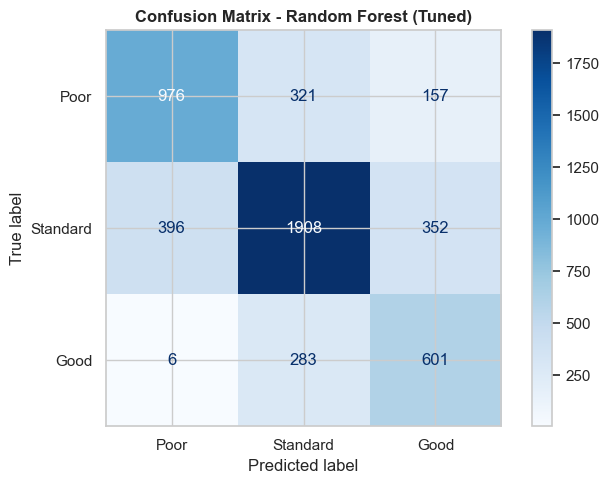


Interpretasi:
  Poor: 976/1454 benar (67.1%)
  Standard: 1908/2656 benar (71.8%)
  Good: 601/890 benar (67.5%)


In [46]:
evaluator.plot_confusion_matrix()

Dari confusion matrix ini kelihatan kalau modelnya paling jago nebak kelas Standard karena emang datanya paling banyak di situ. Kelas Poor dan Good juga lumayan benar nebaknya walau masih sering ketukar sama kelas tengahnya yaitu Standard. Tapi sisi hebatnya model ini pintar misahin dua ekstrem, kayak data yang aslinya Good itu hampir tidak pernah meleset ditebak jadi Poor.

### Feature Importance

Karena sekarang pakai OneHotEncoder, satu kolom kategorikal bisa pecah jadi beberapa kolom one-hot. Makanya nama fitur buat plot importance diambil dari preprocessor.get_feature_names_out(), bukan cuma num_cols + cat_cols mentah

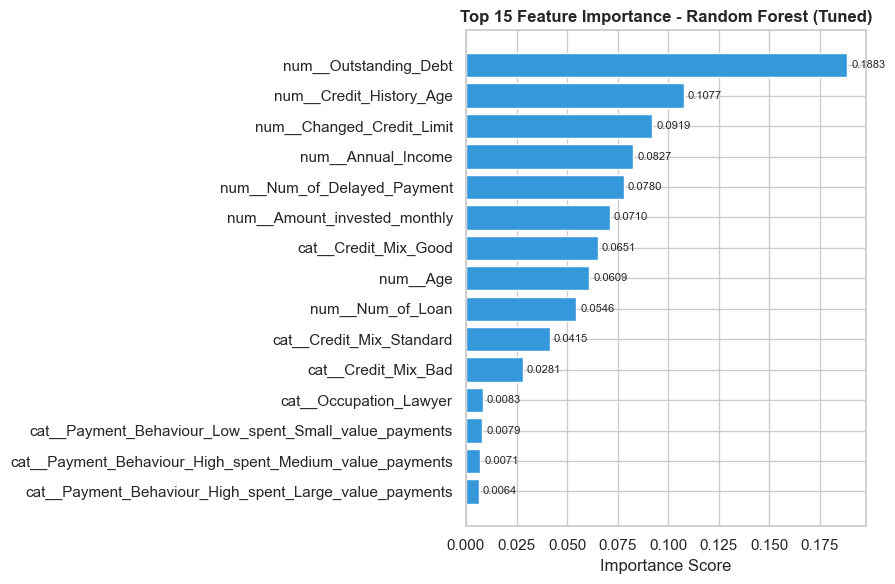

In [47]:
feature_names = preprocessor_obj.preprocessor.get_feature_names_out()
evaluator.plot_feature_importance(feature_names, top_n=15)

jumlah sisa utang atau outstanding debt itu jadi faktor penentu paling dominan buat model Random Forest ini dalam mengambil keputusan. Posisi berikutnya baru disusul sama hal penting lain kayak seberapa lama riwayat kredit dan riwayat perubahan limitnya. Menariknya data yang berupa riwayat angka finansial murni ini jauh lebih ngaruh besar dibandingin sekadar status kategori kayak jenis profesi atau kebiasaan gaya bayar yang skornya nyaris tidak berdampak di urutan paling bawah.

## Ringkasan & Kesimpulan

In [48]:
evaluator.summary()

        RINGKASAN MODEL TERBAIK
  Model              : Random Forest (Tuned)
  Accuracy           : 0.6970  (69.70%)
  Macro Precision    : 0.6698
  Macro Recall       : 0.6883
  Macro F1 Score     : 0.6762


intinya, performa random forest ini bisa dibilang lumayan di angka 69%, walau sebenarnya agak ke-carry sama kelas standard yang datanya emang paling bejibun. modelnya lumayan jago misahin dua kutub ekstrem dia tidak bakal konyol nebak orang yang aslinya 'good' jadi 'poor' tapi saking agresifnya ngasih cap 'good', tebakannya malah sering zonk dan ujung-ujungnya ketukar sama kelas standard. buat ngambil keputusan itu, model ini bener-bener cuma peduli sama angka finansial riil, terutama sisa utang yang jadi bos besarnya, sementara embel-embel status kayak profesi atau gaya bayar nyaris nggak diwaro sama sekali

## Simpan Model Terbaik & kirim Log Evaluasi Final

evaluate() ngitung metrik final     
ekspor ke metrics/evaluation_report.json, dan log ke MLflow.   
save_artifacts() nyimpen model (models/best_model.pkl, pakai joblib + compress karena ukurannya bisa besar) dan metadata kolom (models/model_metadata.pkl, pakai pickle biasa karena isinya kecil). Setelah ini parent run MLflow ditutup.

In [49]:
evaluator.evaluate()
evaluator.save_artifacts()

mlflow.end_run()

# ini saya tambahkan sebagai catatan 
print("\n[INFO] Jalankan perintah `python -m mlflow ui --backend-store-uri sqlite:///mlflow.db --workers 1` di terminal jika mau liat dashboard eksperimennya")


[EVALUASI FINAL]
Nama Model Terpilih : Random Forest (Tuned)
Akurasi             : 0.6970
Macro F1-Score      : 0.6762
[INFO] Laporan performa diekspor ke 'metrics/evaluation_report.json'.


2026/06/26 22:54:12 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/06/26 22:54:12 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


[INFO] File 'model_metadata.pkl' berhasil diamankan di folder 'models/'.

[INFO] Jalankan perintah `python -m mlflow ui --backend-store-uri sqlite:///mlflow.db --workers 1` di terminal jika mau liat dashboard eksperimennya
